# 14 Ablation study
Each row removes one PRESAGE component (single seed, 12 epochs, same chronological split). Differences are interpreted against bootstrap CIs, not raw point estimates.

In [1]:
import sys, pathlib, json, warnings; warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import Image, display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
def table(name):
    p = ROOT / 'reports' / 'tables' / name
    return pd.read_csv(p) if p.exists() else None

In [2]:
import glob
rows = pd.concat([pd.read_csv(f) for f in glob.glob(str(ROOT/'reports/tables/presage_*_s42.csv'))]).drop_duplicates('variant')
rows = rows.sort_values('pr_auc', ascending=False); full = rows.loc[rows.variant=='full','pr_auc'].iloc[0]
rows['delta_vs_full'] = rows.pr_auc - full; rows[['variant','pr_auc','pr_auc_lo','pr_auc_hi','delta_vs_full','recall','precision','f2','mule_pr_auc','train_s']].round(3)

,variant,pr_auc,pr_auc_lo,pr_auc_hi,delta_vs_full,recall,precision,f2,mule_pr_auc,train_s
0,concat,0.982,0.963,0.990,0.062,0.894,0.955,0.905,0.992,429.984
4,no_beh,0.960,0.918,0.978,0.040,0.913,0.963,0.922,0.994,422.222
1,attention,0.943,0.900,0.964,0.023,0.835,0.922,0.851,0.993,444.126
1,no_temporal,0.936,0.892,0.958,0.017,0.855,0.940,0.871,0.984,375.591
6,no_benfeat,0.928,0.892,0.952,0.008,0.897,0.891,0.896,0.980,423.543
2,no_mule,0.921,0.877,0.948,0.002,0.890,0.819,0.875,NaN,454.433
0,full,0.919,0.870,0.951,0.000,0.858,0.953,0.876,0.996,439.078
5,no_txn,0.916,0.872,0.945,-0.004,0.835,0.906,0.849,0.987,418.238
3,no_multitask,0.906,0.857,0.930,-0.014,0.794,0.898,0.812,0.013,442.944
0,no_graph,0.874,0.810,0.907,-0.046,0.835,0.771,0.822,0.858,45.547


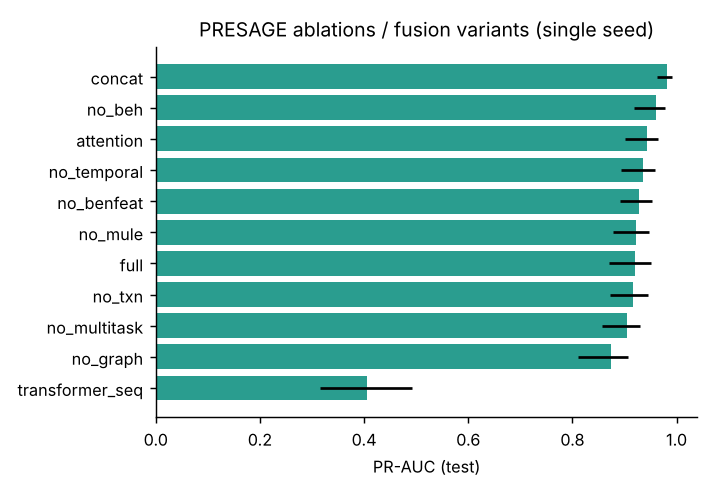

In [3]:
p = ROOT/'reports'/'figures'/'fig_ablation.png'; display(Image(str(p))) if p.exists() else None

Not run as separate rows and why: *without drift adaptation* and *without federated learning* are properties of the training/deployment protocol rather than the network, so they are measured in notebooks 11 (static vs adaptive strategies) and 12 (local vs federated).